## Simulação de reunião

##### Frases longas que simulam uma reunião all hands, com várias áreas e projetos diferentes

In [1]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    # PRODUTO
    "Bom pessoal, começando pelo time de produto, queria compartilhar rapidamente o status da última release, porque tivemos algumas mudanças importantes no escopo que impactaram diretamente o que foi entregue.",
    "De forma geral, conseguimos lançar as funcionalidades principais, mas algumas partes que estavam planejadas inicialmente acabaram ficando para uma próxima versão por questões de prioridade.",
    "Além disso, a gente recebeu bastante feedback dos usuários logo após o lançamento, o que já está ajudando a orientar os próximos ajustes que vamos fazer.",

    # ENGENHARIA
    "Agora, passando para engenharia, acho importante comentar sobre os desafios técnicos que surgiram ao longo desse ciclo, porque tivemos alguns problemas que não estavam no radar.",
    "A principal dificuldade foi na integração com sistemas legados, que acabou consumindo mais tempo do que o previsto inicialmente.",
    "Mesmo assim, o time conseguiu estabilizar o ambiente e hoje a plataforma já está rodando de forma muito mais consistente do que nas últimas semanas.",

    # MARKETING
    "Mudando um pouco de assunto, indo para marketing, a gente teve uma campanha bem relevante rodando junto com o lançamento do produto.",
    "Os resultados iniciais foram positivos, principalmente em termos de aquisição de novos usuários, embora ainda estejamos analisando a qualidade desse tráfego.",
    "Nas próximas semanas, a ideia é otimizar essa campanha com base nos dados que coletamos até agora, focando mais em conversão do que apenas volume.",

    # FINANCEIRO
    "Falando agora de financeiro, tivemos uma revisão do orçamento recente, e alguns pontos chamaram atenção, especialmente relacionados ao aumento de custos operacionais.",
    "Grande parte desse aumento está ligada ao crescimento da infraestrutura e também a algumas contratações que fizemos recentemente.",
    "Por isso, a recomendação é que todas as áreas tenham um pouco mais de atenção com gastos nas próximas semanas, até a gente reequilibrar esse cenário.",

    # RH
    "Indo para o lado de pessoas, o time de RH queria compartilhar algumas atualizações importantes sobre contratações e clima organizacional.",
    "A gente abriu algumas vagas estratégicas nas últimas semanas, principalmente nas áreas de engenharia e produto.",
    "Além disso, estamos rodando uma nova pesquisa interna para entender melhor como está a percepção do time em relação ao ambiente de trabalho.",

    # ESTRATÉGIA / VISÃO
    "Por fim, entrando em estratégia, acho importante reforçar um pouco da direção que a empresa está tomando para os próximos meses.",
    "A prioridade agora é consolidar o que já foi construído, ao invés de sair expandindo para muitas frentes ao mesmo tempo.",
    "Isso significa focar mais em eficiência, qualidade do produto e retenção de usuários, ao invés de crescimento acelerado a qualquer custo.",

    # ENCERRAMENTO
    "Então, de forma geral, esses são os principais pontos de cada área, e a ideia é que a gente siga alinhado nessas prioridades daqui para frente.",
    "Se alguém tiver alguma dúvida ou quiser aprofundar em algum desses temas, a gente pode abrir para perguntas agora."
]
sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4096.46it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(20, 768)
[[ 0.02762915  0.03428954 -0.02204339 ... -0.02427329 -0.02557285
   0.03781739]
 [ 0.02854486  0.03955645 -0.0025635  ... -0.02982523 -0.02481844
   0.03061465]
 [ 0.0382706   0.02346775 -0.03104267 ... -0.02772536 -0.02920172
   0.03272931]
 ...
 [ 0.01551906  0.03147086 -0.0286646  ... -0.02486837 -0.01428698
   0.03771611]
 [ 0.02061454  0.02585332 -0.02825149 ... -0.04654964 -0.033814
   0.03512364]
 [ 0.01987443  0.03610215 -0.03090051 ... -0.04404545 -0.03711715
   0.03527261]]


In [2]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences_e5)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.9518882  0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.96655381 0.93875784 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.96467364 0.94143856 0.95952255 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.94826269 0.94380009 0.95808339 0.95635378 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.


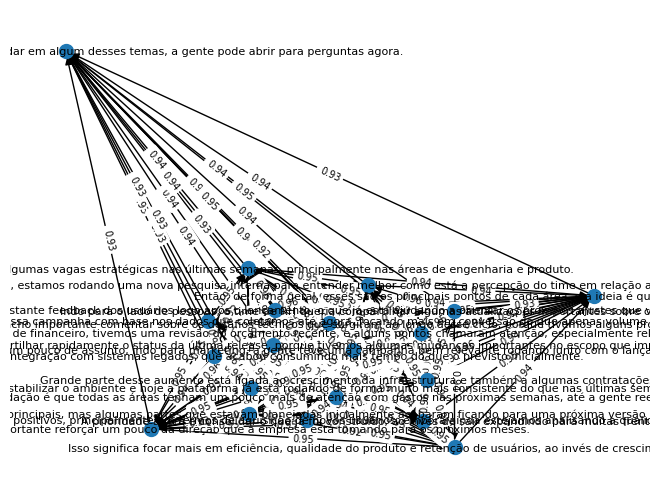

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

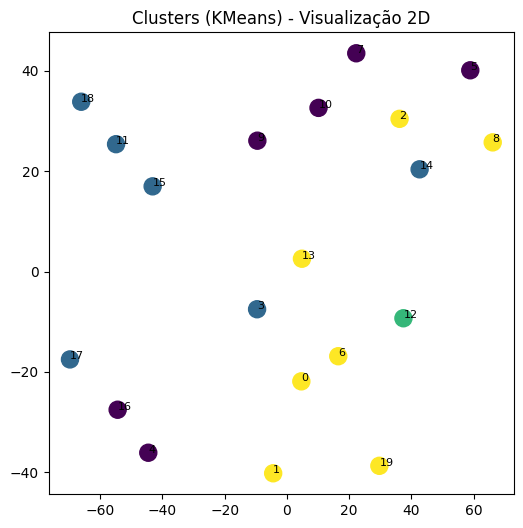

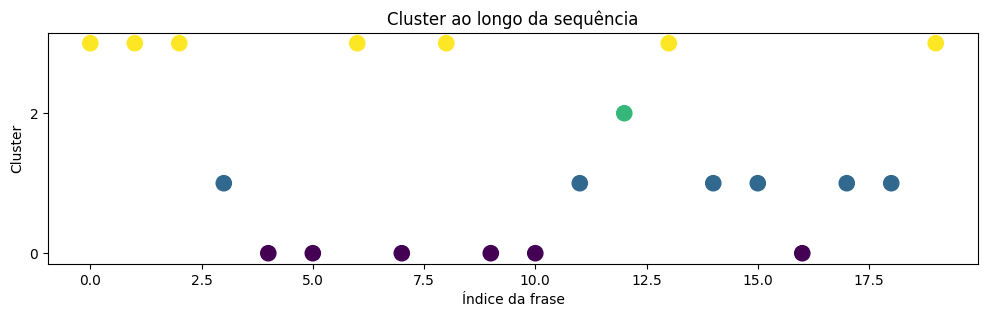

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,2])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

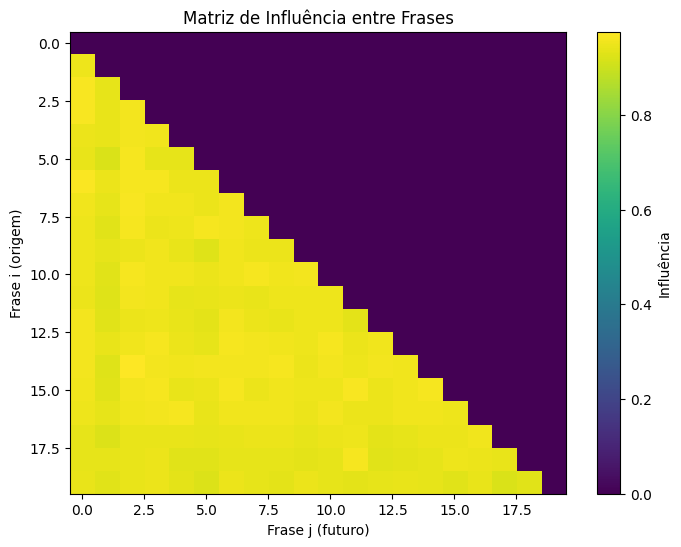

In [5]:
plt.figure(figsize=(8,6))
plt.imshow(A, cmap="viridis", aspect="auto")
plt.colorbar(label="Influência")
plt.title("Matriz de Influência entre Frases")
plt.xlabel("Frase j (futuro)")
plt.ylabel("Frase i (origem)")
plt.show()


 Segmentos detectados:


--- Segmento 1 (0 → 1) ---
- Bom pessoal, começando pelo time de produto, queria compartilhar rapidamente o status da última release, porque tivemos algumas mudanças importantes no escopo que impactaram diretamente o que foi entregue.
- De forma geral, conseguimos lançar as funcionalidades principais, mas algumas partes que estavam planejadas inicialmente acabaram ficando para uma próxima versão por questões de prioridade.

--- Segmento 2 (2 → 4) ---
- Além disso, a gente recebeu bastante feedback dos usuários logo após o lançamento, o que já está ajudando a orientar os próximos ajustes que vamos fazer.
- Agora, passando para engenharia, acho importante comentar sobre os desafios técnicos que surgiram ao longo desse ciclo, porque tivemos alguns problemas que não estavam no radar.
- A principal dificuldade foi na integração com sistemas legados, que acabou consumindo mais tempo do que o previsto inicialmente.

--- Segmento 3 (5 → 11) ---
- Mesmo assim, o time c

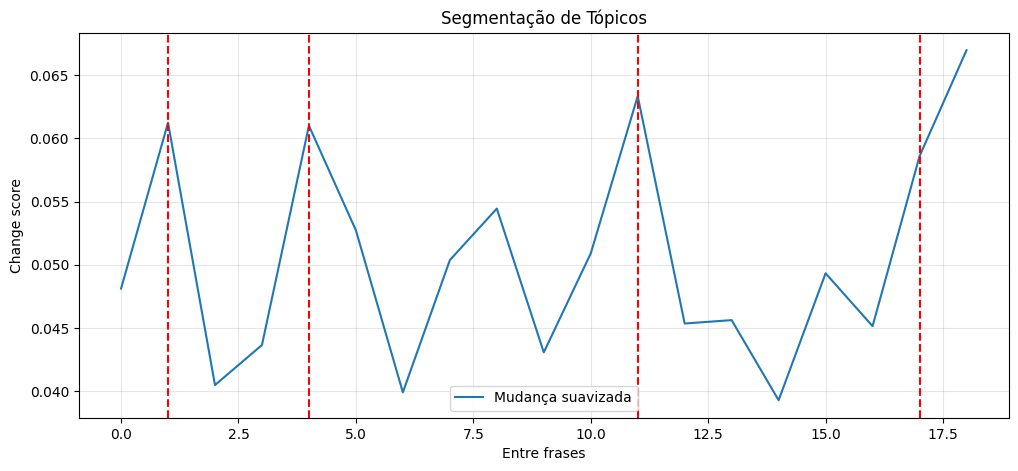

In [10]:
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)
n = len(S_norm)

adj_sim = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(n - 1)
])

change = 1 - adj_sim

window = 1
kernel = np.ones(window) / window
change_smooth = np.convolve(change, kernel, mode='same')

threshold = np.mean(change_smooth) + 0.87 * np.std(change_smooth)

split_points = np.where(change_smooth > threshold)[0]

min_distance = 2
filtered_splits = []

for idx in split_points:
    if not filtered_splits or idx - filtered_splits[-1] > min_distance:
        filtered_splits.append(idx)

split_points = filtered_splits

segments = []
start = 0

for idx in split_points:
    segments.append((start, idx+1))
    start = idx+1

segments.append((start, n))

print("\n Segmentos detectados:\n")

for i, (s, e) in enumerate(segments):
    print(f"\n--- Segmento {i+1} ({s} → {e-1}) ---")
    for sent in sentences[s:e]:
        print("-", sent)


print("\n Rótulos dos segmentos:\n")

for i, (s, e) in enumerate(segments):
    mid = (s + e) // 2
    print(f"Segmento {i+1}: {sentences[mid]}")


plt.figure(figsize=(12,5))

plt.plot(change_smooth, label="Mudança suavizada")

for idx in split_points:
    plt.axvline(idx, color='red', linestyle='--')

plt.title("Segmentação de Tópicos")
plt.xlabel("Entre frases")
plt.ylabel("Change score")

plt.legend()
plt.grid(alpha=0.3)

plt.show()